# Make scRNA-seq toy data from Zebrahub scRNA-seq data

28 Oct 2026

In [1]:
suppressPackageStartupMessages(library(Seurat))
library(tidyverse)
set.seed(42)

-- Attaching core tidyverse packages --------------- tidyverse 2.0.0 --
v dplyr     1.2.1     v readr     2.2.0
v forcats   1.0.1     v stringr   1.6.0
v ggplot2   4.0.3     v tibble    3.3.1
v lubridate 1.9.5     v tidyr     1.3.2
v purrr     1.2.2     
-- Conflicts --------------------------------- tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
# Find all the h5 file paths automatically
sample_dirs <- list.dirs(path = "zebrahub_data/count_matrices", full.names = TRUE, recursive = FALSE)
h5_files <- file.path(sample_dirs, "filtered_feature_bc_matrix.h5")

# Keep only paths where the file actually exists
h5_files <- h5_files[file.exists(h5_files)]

# Extract sample names from the directory names (e.g., "TDR18")
names(h5_files) <- basename(sample_dirs[file.exists(h5_files)])

# Read all data into a named list
seurat_data_list <- lapply(h5_files, function(file) {
  Read10X_h5(file)
})

In [4]:
# Create a list of Seurat objects
seurat_list <- imap(seurat_data_list, function(counts, sample_name) {
  suppressWarnings(CreateSeuratObject(
    counts = counts, 
    project = sample_name, 
    min.cells = 3, 
    min.features = 200
  ))
})

In [5]:
# Merge all objects together (adds prefixes to cell names to avoid overlap)
combined_seurat <- merge(
  x = seurat_list[[1]], 
  y = seurat_list[-1], 
  add.cell.ids = names(seurat_list)
)

# Inspect the combined object
combined_seurat

An object of class Seurat 
28076 features across 535307 samples within 1 assay 
Active assay: RNA (28076 features, 0 variable features)
 40 layers present: counts.TDR18, counts.TDR19, counts.TDR21, counts.TDR22, counts.TDR23, counts.TDR24, counts.TDR25, counts.TDR26, counts.TDR27, counts.TDR28, counts.TDR29, counts.TDR30, counts.TDR35, counts.TDR36, counts.TDR37, counts.TDR38, counts.TDR39, counts.TDR40, counts.TDR41, counts.TDR42, counts.TDR43, counts.TDR44, counts.TDR45, counts.TDR46, counts.TDR47, counts.TDR48, counts.TDR49, counts.TDR50, counts.TDR51, counts.TDR52, counts.TDR53, counts.TDR54, counts.TDR67, counts.TDR68, counts.TDR69, counts.TDR70, counts.TDR71, counts.TDR72, counts.TDR73, counts.TDR74

### Downsample 200

In [57]:
Idents(combined_seurat) <- "orig.ident"          
toy <- subset(combined_seurat, downsample = 200) 
system.time({
  toy <- NormalizeData(toy, verbose = FALSE)
  toy <- FindVariableFeatures(toy, nfeatures = 2000, verbose = FALSE)
  toy <- ScaleData(toy, verbose = FALSE)
  toy <- RunPCA(toy, npcs = 30, verbose = FALSE)
  toy <- IntegrateLayers(
      object         = toy,
      method         = HarmonyIntegration,   # needs the 'harmony' package
      orig.reduction = "pca",
      new.reduction  = "harmony",
      verbose        = FALSE)
  toy <- FindNeighbors(toy, dims = 1:30, verbose = FALSE)
  toy <- FindClusters(toy, resolution = 0.5, verbose = FALSE)
  toy <- RunUMAP(toy, dims = 1:30, verbose = FALSE)
})
saveRDS(toy, "zebrahub_data/toy_seurat.rds")

Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.30103”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  5.6666e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.3219”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.49803”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  2.6613e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“There are other near singularities as well. 0.090619”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at

   user  system elapsed 
136.896   1.395 131.135 

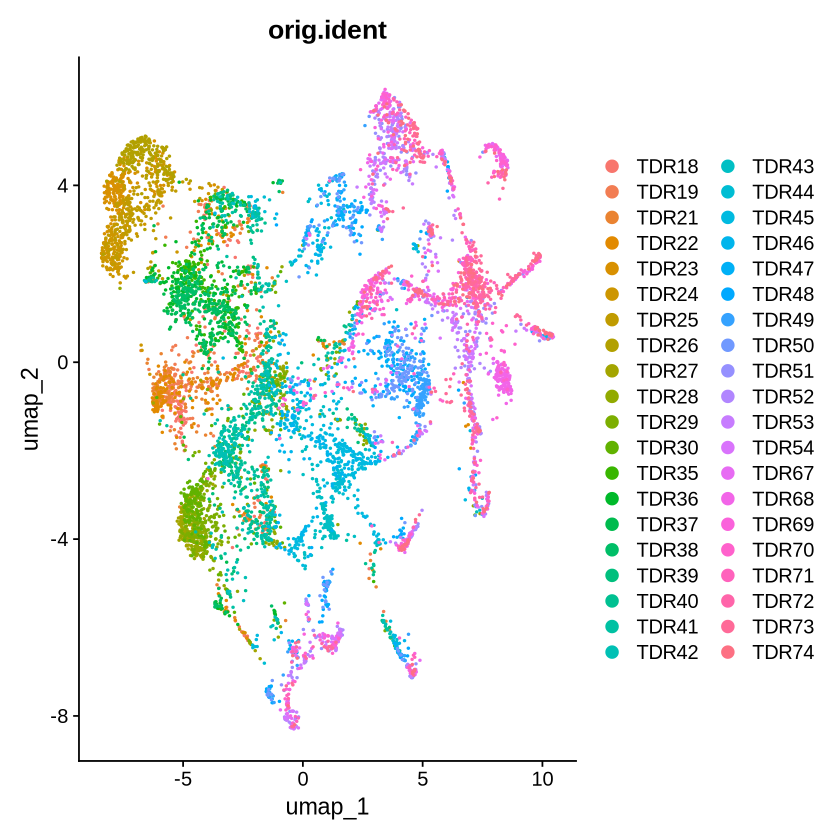

In [58]:
DimPlot(toy, group.by = "orig.ident")

### Downsample 300

In [59]:
Idents(combined_seurat) <- "orig.ident"          
toy <- subset(combined_seurat, downsample = 300) 
system.time({
  toy <- NormalizeData(toy, verbose = FALSE)
  toy <- FindVariableFeatures(toy, nfeatures = 2000, verbose = FALSE)
  toy <- ScaleData(toy, verbose = FALSE)
  toy <- RunPCA(toy, npcs = 30, verbose = FALSE)
  toy <- IntegrateLayers(
      object         = toy,
      method         = HarmonyIntegration,   # needs the 'harmony' package
      orig.reduction = "pca",
      new.reduction  = "harmony",
      verbose        = FALSE)
  toy <- FindNeighbors(toy, dims = 1:30, verbose = FALSE)
  toy <- FindClusters(toy, resolution = 0.5, verbose = FALSE)
  toy <- RunUMAP(toy, dims = 1:30, verbose = FALSE)
})
saveRDS(toy, "zebrahub_data/toy_seurat.rds")

Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.1761”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.30103”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  2.6477e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.4996”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.49959”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  7.7865e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“There are other near singularities as well. 0.090619”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse us

   user  system elapsed 
156.589   1.599 127.196 

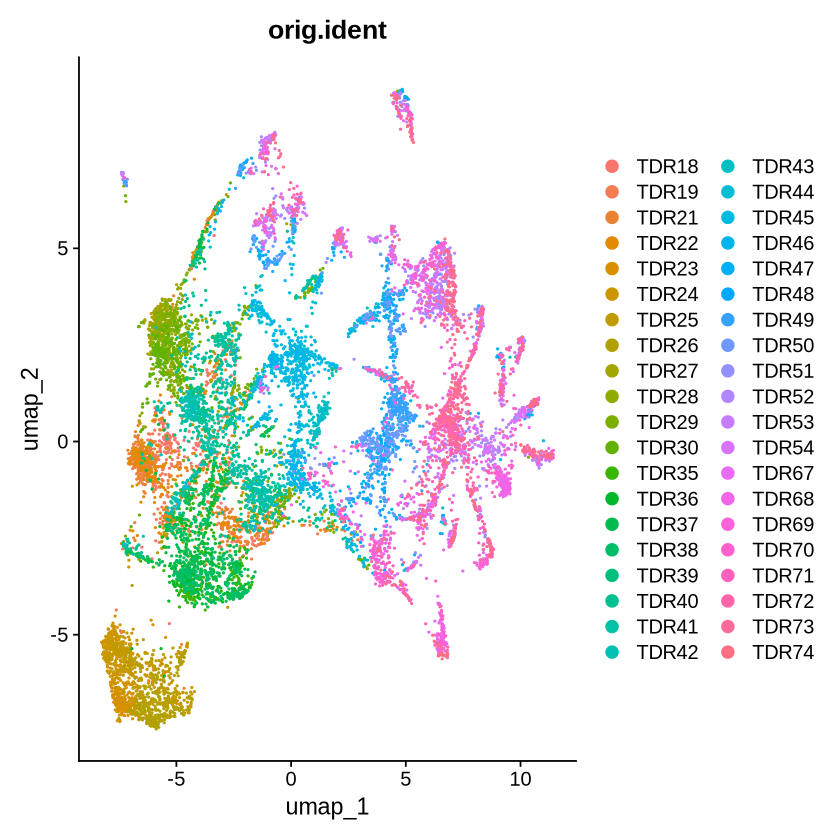

In [60]:
DimPlot(toy, group.by = "orig.ident")

### Downsample 300 + Harmony

Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.1761”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.30103”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  2.6477e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.4996”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.49959”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  7.7865e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“There are other near singularities as well. 0.090619”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse us

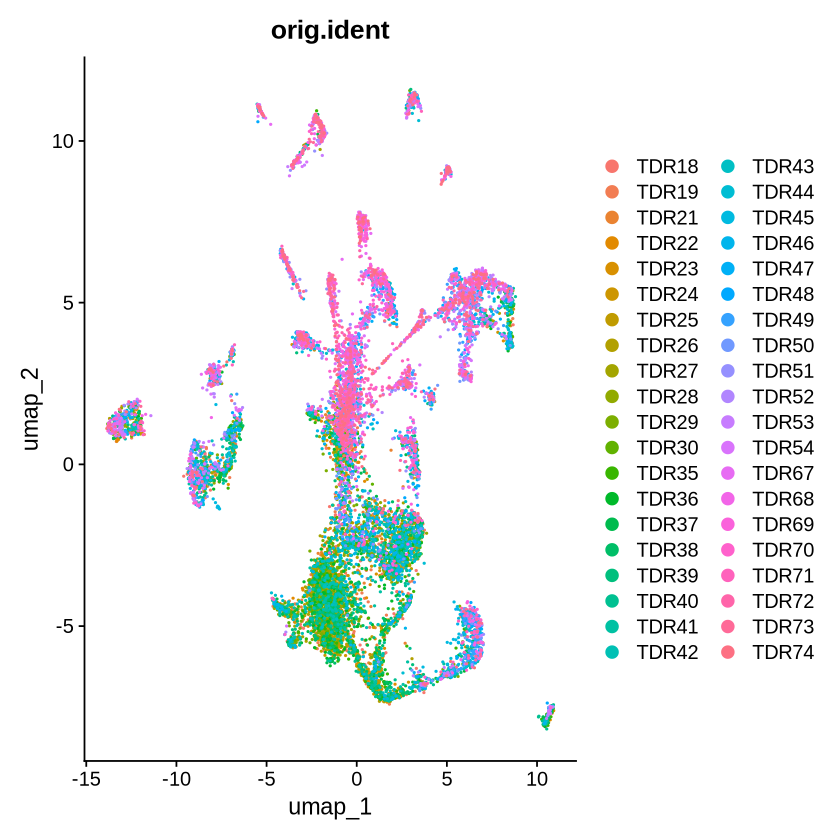

In [64]:
toy <- subset(combined_seurat, downsample = 300) 
toy <- NormalizeData(toy, verbose = FALSE)
toy <- FindVariableFeatures(toy, verbose = FALSE)
toy <- ScaleData(toy, verbose = FALSE)
toy <- RunPCA(toy, npcs = 30, verbose = FALSE)

toy <- IntegrateLayers(
  object         = toy,
  method         = HarmonyIntegration,   # needs the 'harmony' package
  orig.reduction = "pca",
  new.reduction  = "harmony",
  verbose        = FALSE)

# cluster + UMAP on the CORRECTED  reduction, not pca
toy <- FindNeighbors(toy, reduction = "harmony", dims = 1:30, verbose = FALSE)
toy <- FindClusters(toy, resolution = 0.3, verbose = FALSE)
toy <- RunUMAP(toy, reduction = "harmony", dims = 1:30, verbose = FALSE)

toy <- JoinLayers(toy)   # afterwards, so FindAllMarkers works on one matrix
DimPlot(toy, group.by = "orig.ident")

## Save the count matrix

In [65]:
saveRDS(toy, "zebrahub_data/toy_seurat.rds")

In [69]:
head(LayerData(toy, layer = "counts"))

  [[ suppressing 12000 column names ‘TDR18_AAACGCTCAAGAGTAT-1’, ‘TDR18_AAAGGATCAATTTCCT-1’, ‘TDR18_AACCAACTCTTTCCAA-1’ ... ]]



6 x 12000 sparse Matrix of class "dgCMatrix"
                                                                               
ptpn12          . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
phtf2           . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
phtf2.1         . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
CU856344.1      . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
si:zfos-932h1.3 . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
mansc1          . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
                                                                               
ptpn12          . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
phtf2           . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
phtf2.1         . . . . . . . . . . . . . . . 1 . . . . . . . . . . . . . . . .
CU856344.1      . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .

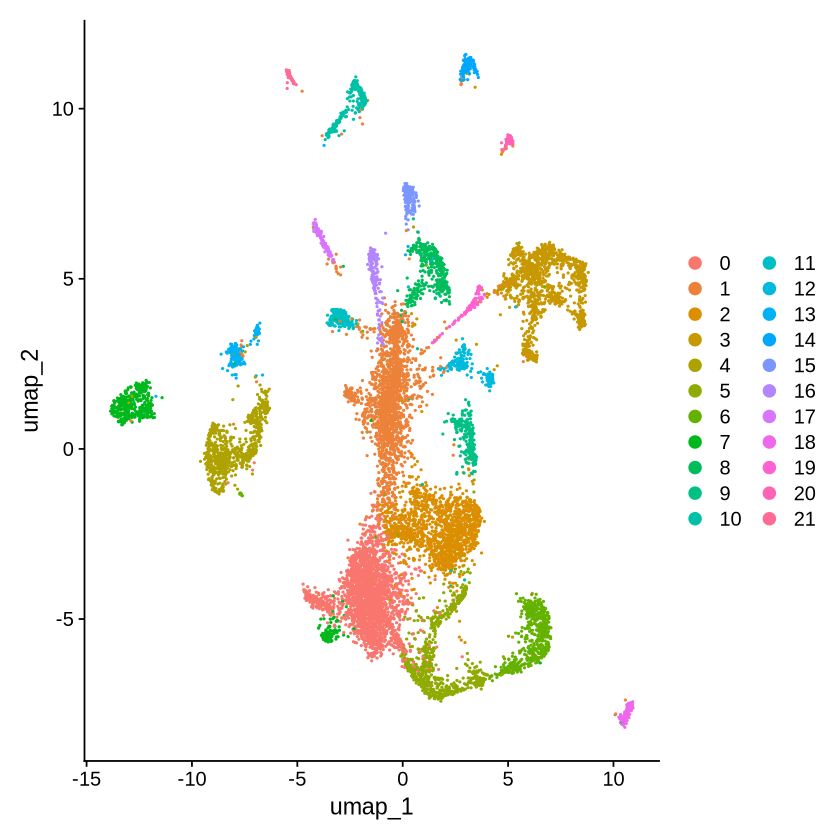

In [66]:
toy <- readRDS("zebrahub_data/toy_seurat.rds")   
DimPlot(toy)